# WV County Overdose Deaths: Step 1 (Prepare the data)
Source: 2025 County Health Rankings West Virginia data (v3), CHR&R.

In [1]:
import pandas as pd, numpy as np
np.random.seed(42)

PATH = "data/2025_County_Health_Rankings_West_Virginia_Data_-_v3.xlsx"
sel = pd.read_excel(PATH, sheet_name="Select Measure Data", header=1)
add = pd.read_excel(PATH, sheet_name="Additional Measure Data", header=1)
print(sel.shape, add.shape)

(56, 225) (56, 395)


In [3]:
# Merge the two sheets by county FIPS code
a = sel[["FIPS", "County", "% Unemployed", "Mental Health Provider Rate"]]
b = add[["FIPS", "Drug Overdose Mortality Rate", "Median Household Income", "% Frequent Mental Distress"]]
df = a.merge(b, on="FIPS", how="inner")

# Remove the statewide row (it has no county name)
df = df[df["County"].notna()].copy()
print(df.shape)  # 55 counties

(55, 7)


In [5]:
# Rename columns and keep six: county + five measures
df = df.rename(columns={
    "County": "county",
    "Drug Overdose Mortality Rate": "overdose_rate",
    "% Unemployed": "unemployment",
    "Median Household Income": "median_income",
    "% Frequent Mental Distress": "mental_distress",
    "Mental Health Provider Rate": "mh_providers_rate",
})[["county", "overdose_rate", "unemployment", "median_income", "mental_distress", "mh_providers_rate"]]

# Counties with no overdose value (fewer than 10 deaths in 3 years)
removed = df.loc[df["overdose_rate"].isna(), "county"].tolist()
print(len(removed), "counties removed:", removed)

df = df.dropna(subset=["overdose_rate"]).reset_index(drop=True)
print(df.shape)  # expect (45, 6)
assert df.shape == (45, 6)
assert df.isna().sum().sum() == 0

10 counties removed: ['Calhoun', 'Doddridge', 'Gilmer', 'Pendleton', 'Pleasants', 'Ritchie', 'Roane', 'Tucker', 'Webster', 'Wirt']
(45, 6)


In [7]:
df.to_csv("data/clean_wv.csv", index=False)
df.head()

,county,overdose_rate,unemployment,median_income,mental_distress,mh_providers_rate
0,Barbour,38.034062,4.844339,51353,23.7,123.55313
1,Berkeley,77.313310,3.403996,78995,19.5,207.64120
2,Boone,108.944501,4.205156,48034,23.9,43.74028
3,Braxton,68.180626,5.063291,50038,24.0,98.66798
4,Brooke,68.653028,5.018107,49187,21.7,46.78800


count     45.000000
mean      76.107803
std       35.779996
min       27.448594
25%       48.452547
50%       63.470141
75%       99.608153
max      180.692277
Name: overdose_rate, dtype: float64
      county  overdose_rate
20  McDowell     180.692277
19     Logan     164.361046
35   Raleigh     137.995109
5     Cabell     131.779345
44   Wyoming     119.933226
      county  overdose_rate
36  Randolph      27.448594
40    Upshur      34.851463
33   Preston      36.306545
0    Barbour      38.034062
22  Marshall      41.124819


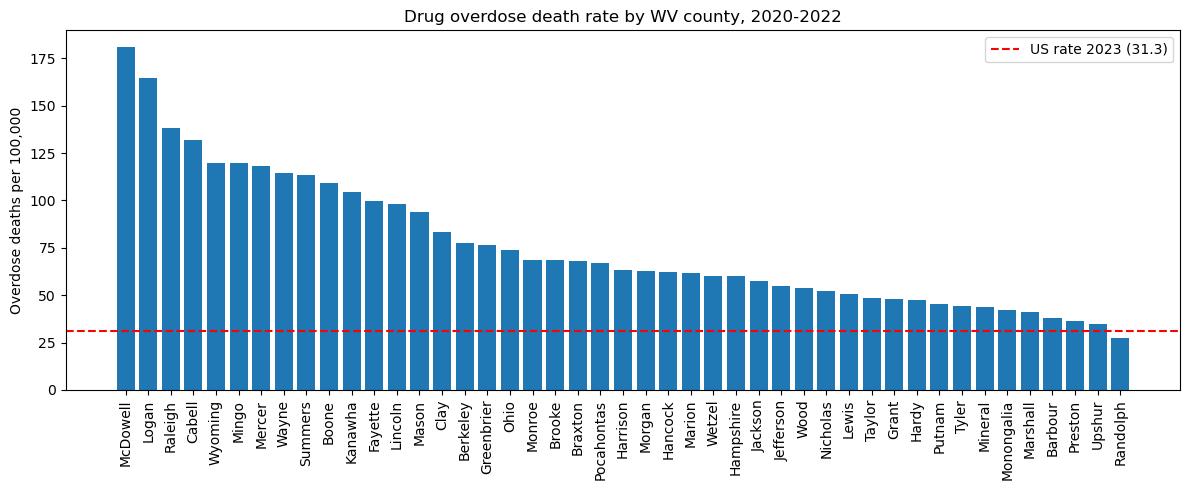

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/clean_wv.csv")
print(df["overdose_rate"].describe())
print(df.nlargest(5, "overdose_rate")[["county", "overdose_rate"]])
print(df.nsmallest(5, "overdose_rate")[["county", "overdose_rate"]])

d = df.sort_values("overdose_rate", ascending=False)
plt.figure(figsize=(12, 5))
plt.bar(d["county"], d["overdose_rate"])
plt.axhline(31.3, color="red", linestyle="--", label="US rate 2023 (31.3)")
plt.title("Drug overdose death rate by WV county, 2020-2022")
plt.xticks(rotation=90)
plt.ylabel("Overdose deaths per 100,000")
plt.legend()
plt.tight_layout()
plt.show()

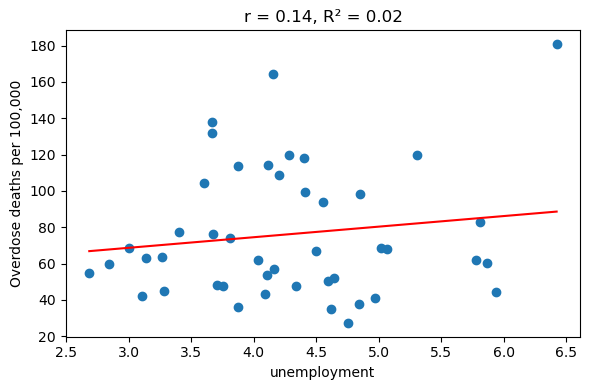

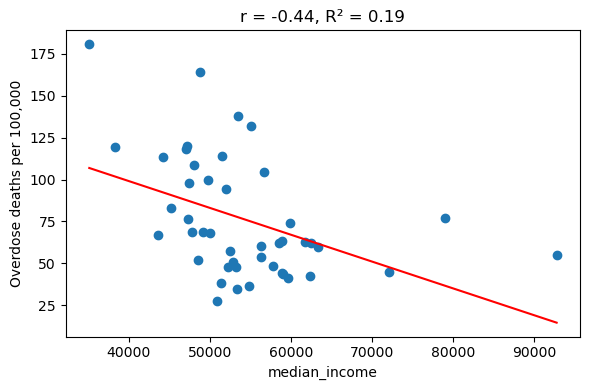

,factor,r,slope,r2
1,median_income,-0.438159,-0.001602,0.191983
0,unemployment,0.141202,5.822351,0.019938


In [10]:
from helpers import plot_and_fit

factors = ["unemployment", "median_income"]
results = [plot_and_fit(df, c) for c in factors]
pd.DataFrame(results).sort_values("r2", ascending=False)

In [13]:
cols = ["overdose_rate", "unemployment", "median_income", "mental_distress", "mh_providers_rate"]
df[cols].corr().round(2)

,overdose_rate,unemployment,median_income,mental_distress,mh_providers_rate
overdose_rate,1.00,0.14,-0.44,0.51,0.16
unemployment,0.14,1.00,-0.53,0.52,-0.33
median_income,-0.44,-0.53,1.00,-0.78,0.17
mental_distress,0.51,0.52,-0.78,1.00,-0.31
mh_providers_rate,0.16,-0.33,0.17,-0.31,1.00


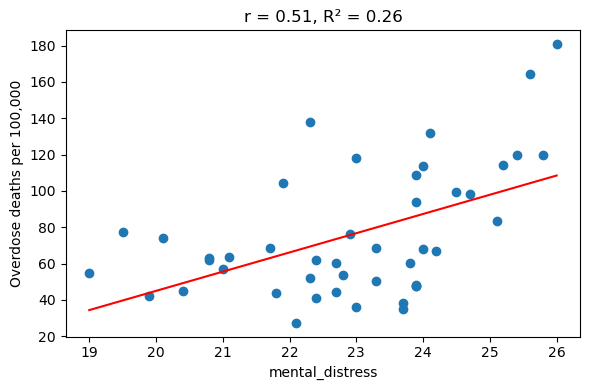

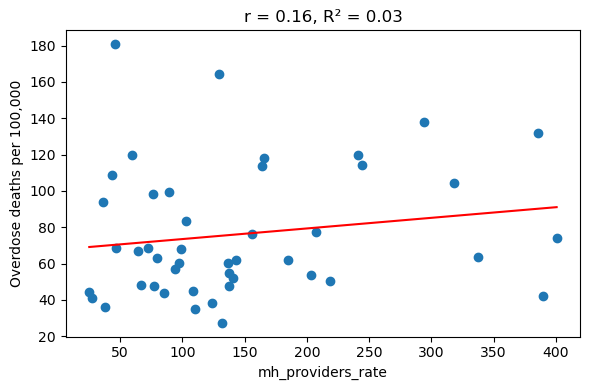

,factor,r,slope,r2
0,mental_distress,0.511329,10.582447,0.261458
1,mh_providers_rate,0.164366,0.058450,0.027016


In [15]:
from helpers import plot_and_fit
factors = ["mental_distress", "mh_providers_rate"]
results = [plot_and_fit(df, c) for c in factors]
pd.DataFrame(results).sort_values("r2", ascending=False)

In [17]:
from helpers import FACTORS
no_out = df.drop(df["overdose_rate"].idxmax())
print("dropped:", df.loc[df["overdose_rate"].idxmax(), "county"])
rows = []
for c in FACTORS:
    r_all = np.corrcoef(df[c], df["overdose_rate"])[0, 1]
    r_no = np.corrcoef(no_out[c], no_out["overdose_rate"])[0, 1]
    rows.append({"factor": c, "r_all": r_all, "r2_all": r_all**2, "r_no": r_no, "r2_no": r_no**2})
pd.DataFrame(rows).round(3)

dropped: McDowell


,factor,r_all,r2_all,r_no,r2_no
0,unemployment,0.141,0.020,-0.033,0.001
1,median_income,-0.438,0.192,-0.357,0.127
2,mental_distress,0.511,0.261,0.454,0.206
3,mh_providers_rate,0.164,0.027,0.262,0.068


In [19]:
from helpers import cross_validate, baseline_predict, four_factor_predict
res = cross_validate(df, {"baseline": baseline_predict, "four_factor": four_factor_predict})
print(res.describe().round(2))
print("four_factor wins in", (res["four_factor"] < res["baseline"]).mean() * 100, "% of splits")

       baseline  four_factor
count    100.00       100.00
mean      34.46        30.75
std        8.47         7.61
min       19.80        14.42
25%       28.40        25.28
50%       32.46        29.53
75%       39.84        34.01
max       57.17        56.87
four_factor wins in 81.0 % of splits


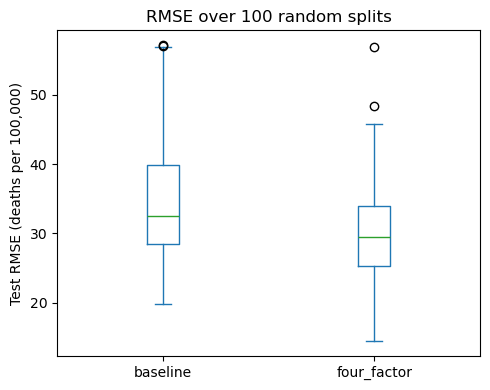

In [21]:
import matplotlib.pyplot as plt
res.plot.box(figsize=(5, 4))
plt.ylabel("Test RMSE (deaths per 100,000)")
plt.title("RMSE over 100 random splits")
plt.tight_layout()
plt.show()

## Data dictionary
| Column | Meaning | Unit | Period |
| --- | --- | --- | --- |
| county | County name | text | n/a |
| overdose_rate | Drug poisoning deaths | per 100,000 people | 2020-2022 |
| unemployment | Population 16+ unemployed but seeking work | % | 2023 |
| median_income | Income at which half of households earn more and half earn less | US dollars | 2023 and 2019-2023 |
| mental_distress | Adults reporting 14+ poor mental health days per month (age-adjusted) | % | 2022 |
| mh_providers_rate | Mental health providers | per 100,000 people | 2024 |